## Step 1: Import Libraries and Load Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Check if dataset exists
csv_path = 'ai_job_skills.csv'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print(f"Dataset loaded successfully! Total rows: {len(df)}")
    print(df.head(2))
else:
    print("Error: ai_job_skills.csv not found! Please run the preprocessing or training script first.")

Dataset loaded successfully! Total rows: 14184
                                            job_link  \
0  https://www.linkedin.com/jobs/view/senior-soft...   
1  https://www.linkedin.com/jobs/view/java-softwa...   

                                          job_skills  \
0  Java, Linux, Docker, Kubernetes, AWS, Software...   
1  Software Development, Java, PostgreSQL, MySQL,...   

                       job_title            company  
0  Senior Software Engineer C3Bm            Ga Ccri  
1         Java Software Engineer  Stem Search Group  


In [14]:
df.head(5)

,job_link,job_skills,job_title,company,domain
0,https://www.linkedin.com/jobs/view/senior-soft...,"Java, Linux, Docker, Kubernetes, AWS, Software...",Senior Software Engineer C3Bm,Ga Ccri,Software Engineering & Infrastructure
1,https://www.linkedin.com/jobs/view/java-softwa...,"Software Development, Java, PostgreSQL, MySQL,...",Java Software Engineer,Stem Search Group,Software Engineering & Infrastructure
2,https://www.linkedin.com/jobs/view/senior-soft...,"Software Engineering, Android Development, Kot...",Senior Software Engineer Android,Jobs For Humanity,Software Engineering & Infrastructure
3,https://www.linkedin.com/jobs/view/senior-soft...,"ReactJS, UI/UX design, Product management, Mar...",Senior Software Engineer Digital Technology,Vuori,Software Engineering & Infrastructure
4,https://uk.linkedin.com/jobs/view/software-eng...,"C, C++, Java, SQL, JavaRx, LLDB, GDB, RDMA, Do...",Software Engineer,Yellowbrick Data,Software Engineering & Infrastructure


In [15]:
df.tail(5)

,job_link,job_skills,job_title,company,domain
14179,https://uk.linkedin.com/jobs/view/backend-soft...,"Python, Programming languages, Product shippin...",Backend Software Engineer,Grasp,Software Engineering & Infrastructure
14180,https://www.linkedin.com/jobs/view/cleared-dat...,"Data Strategy, Data Collection, Data Quality, ...",Cleared Data Analyst,Guidehouse,Data Analytics
14181,https://www.linkedin.com/jobs/view/senior-soft...,"JavaScript, Java, Python, Go, TypeScript, SQL,...",Senior Software Engineer Full Stack Golang,Clickjobs Io,Software Engineering & Infrastructure
14182,https://www.linkedin.com/jobs/view/senior-soft...,"Embedded firmware/software development, Image ...",Senior Software Engineer San Francisco,Focal Systems,Software Engineering & Infrastructure
14183,https://www.linkedin.com/jobs/view/senior-soft...,"Java, JavaScript, Spring Boot, Low latency sys...",Senior Software Engineer Asset Wealth Manageme...,Goldman Sachs,Software Engineering & Infrastructure


## Step 2: Categorize Jobs into Core AI Domains
We group job descriptions into distinct domains based on keywords in their job titles.

/tmp/ipykernel_12755/1124648951.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='domain', data=df_clean, order=df_clean['domain'].value_counts().index, palette='viridis')


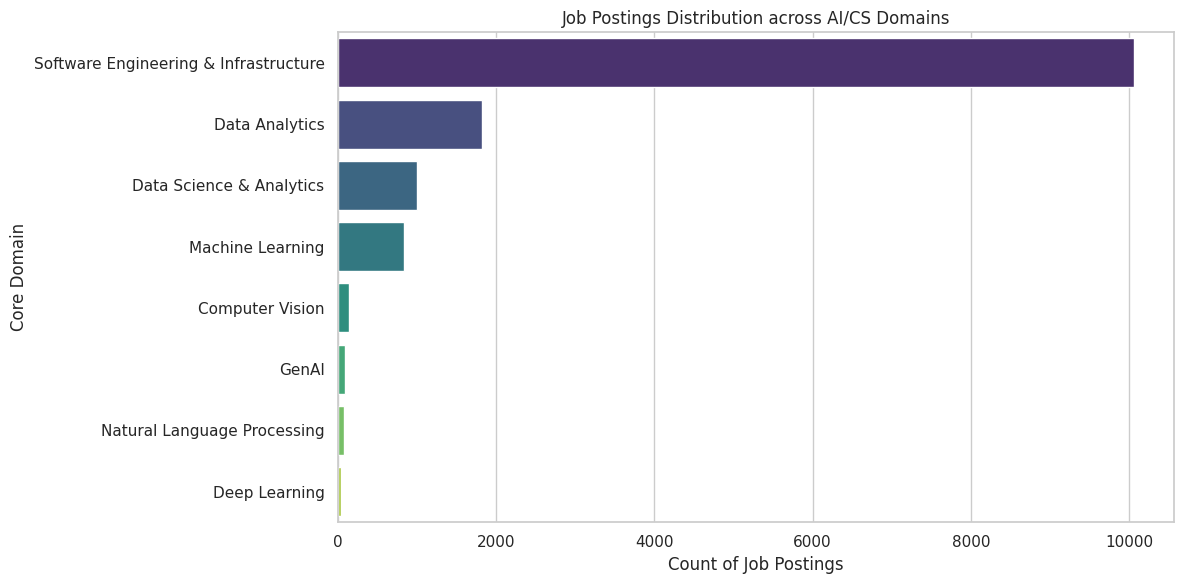

In [3]:
def categorize_job(title):
    title_lower = str(title).lower()
    
    # GenAI / generative AI specific keywords (place first to capture LLM/generative roles)
    if any(k in title_lower for k in ['genai', 'gen ai', 'generative', 'generative ai', 'gpt', 'gpt-', 'chatgpt', 'dall-e', 'dall e', 'dalle', 'stable diffusion', 'midjourney', 'diffusion model', 'llm']):
        return 'GenAI'
    if any(k in title_lower for k in ['deep learning', 'neural network', 'pytorch', 'tensorflow', 'keras']):
        return 'Deep Learning'
    elif any(k in title_lower for k in ['nlp', 'natural language', 'speech', 'text mining', 'translation', 'language model', 'llm', 'bert']):
        return 'Natural Language Processing'
    elif any(k in title_lower for k in ['vision', 'image', 'opencv', 'object detection', 'graphics', 'ocr']):
        return 'Computer Vision'
    elif any(k in title_lower for k in ['machine learning', 'ml ', 'ml-', 'mlops', 'reinforcement learning', 'predictive']):
        return 'Machine Learning'
    elif any(k in title_lower for k in ['data scientist', 'data science', 'statistician', 'statistics', 'quantitative analyst', 'quant']):
        return 'Data Science & Analytics'
    elif any(k in title_lower for k in ['software', 'developer', 'engineer', 'architect', 'devops', 'backend', 'frontend', 'full stack', 'cloud', 'systems']):
        return 'Software Engineering & Infrastructure'
    elif any(k in title_lower for k in ['data analyst', 'business analyst', 'bi analyst', 'analytics engineer', 'data specialist']):
        return 'Data Analytics'
    else:
        return 'Other CS/IT'

df['domain'] = df['job_title'].apply(categorize_job)

# Filter out 'Other CS/IT' and missing records
df_clean = df[df['domain'] != 'Other CS/IT'].dropna(subset=['job_skills', 'domain'])

# Display class distribution
plt.figure(figsize=(12, 6))
sns.countplot(y='domain', data=df_clean, order=df_clean['domain'].value_counts().index, palette='viridis')
plt.title('Job Postings Distribution across AI/CS Domains')
plt.xlabel('Count of Job Postings')
plt.ylabel('Core Domain')
plt.tight_layout()
plt.show()


## Step 3: Text Preprocessing & Vectorization (TF-IDF)
We transform the list of comma-separated skills into space-separated text, and vectorize them using TF-IDF.

In [4]:
# Preprocess comma-separated list into text tokens
df_clean['skills_text'] = df_clean['job_skills'].apply(lambda x: str(x).replace(',', ' '))

X = df_clean['skills_text']
y = df_clean['domain']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Vectorize features using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english', sublinear_tf=True)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f"Vocabulary size: {len(vectorizer.vocabulary_)}")
print(f"Training shape: {X_train_vec.shape}")

Vocabulary size: 5000
Training shape: (11281, 5000)


## Step 4: Model Training and Evaluation
We train Naive Bayes, Decision Tree, and Random Forest. We calculate Accuracy, Precision, Recall, and F1-Score for each.

In [5]:
models = {
    'Naive Bayes': MultinomialNB(),
    'Decision Tree': DecisionTreeClassifier(max_depth=20, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=25, random_state=42, n_jobs=-1)
}

metrics_results = {}
reports = {}

for name, model in models.items():
    # Fit model
    model.fit(X_train_vec, y_train)
    y_pred = model.predict(X_test_vec)
    
    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)
    
    metrics_results[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }
    
    # Store classification report text for later display
    reports[name] = classification_report(y_test, y_pred, zero_division=0)
    
    print(f"Trained: {name}")


Trained: Naive Bayes
Trained: Decision Tree
Trained: Random Forest


In [6]:
# Summary: display Accuracy, Precision, Recall, F1-Score for each model (in percent)
import pandas as pd
metrics_df = pd.DataFrame(metrics_results).T[['Accuracy','Precision','Recall','F1-Score']]
metrics_df = (metrics_df * 100).round(2)
metrics_df.index.name = 'Model'
metrics_df


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Naive Bayes,88.90,87.72,88.90,87.58
Decision Tree,86.07,85.75,86.07,85.85
Random Forest,89.97,89.58,89.97,89.02


In [7]:
# Print classification reports per model (separate outputs for readability)
for name, report in reports.items():
    print('\n' + '='*40)
    print(f'Classification Report - {name}')
    print('='*40)
    print(report)



Classification Report - Naive Bayes
                                       precision    recall  f1-score   support

                      Computer Vision       1.00      0.31      0.47        29
                       Data Analytics       0.79      0.91      0.85       365
             Data Science & Analytics       0.69      0.52      0.59       201
                        Deep Learning       0.00      0.00      0.00         9
                                GenAI       1.00      0.05      0.10        19
                     Machine Learning       0.73      0.55      0.63       169
          Natural Language Processing       0.00      0.00      0.00        16
Software Engineering & Infrastructure       0.93      0.98      0.95      2013

                             accuracy                           0.89      2821
                            macro avg       0.64      0.42      0.45      2821
                         weighted avg       0.88      0.89      0.88      2821


Classificat

## Step 5: Visualizing Model Comparisons
Let's plot a grouped bar chart comparing the three classification algorithms.

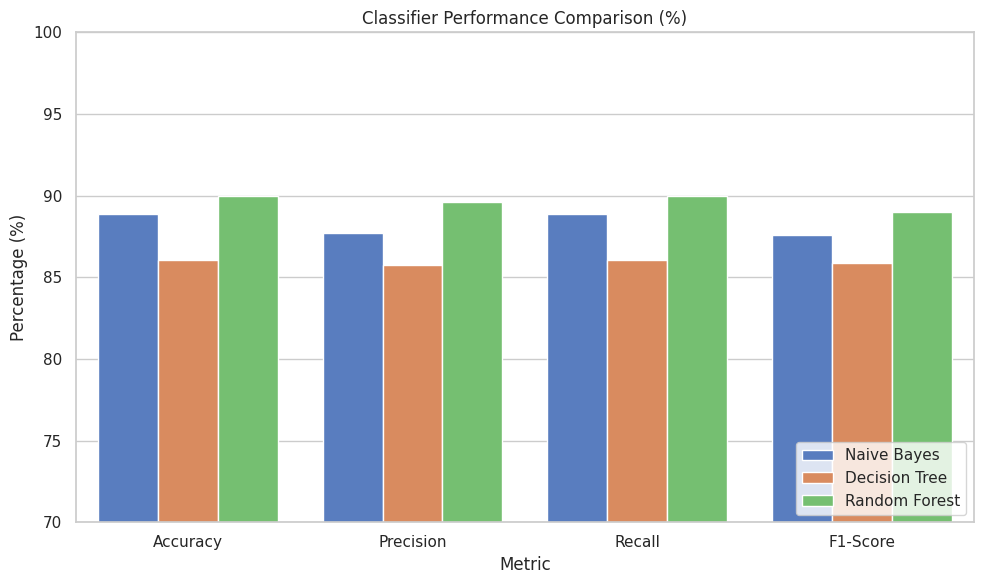

In [9]:
# Reshape metrics results for plotting
lot_data = []
for model_name, metrics in metrics_results.items():
    for metric_name, val in metrics.items():
        plot_data.append({
            'Model': model_name,
            'Metric': metric_name,
            'Value': val * 100
        })

plot_df = pd.DataFrame(plot_data)

plt.figure(figsize=(10, 6))
sns.barplot(x='Metric', y='Value', hue='Model', data=plot_df, palette='muted')
plt.title('Classifier Performance Comparison (%)')
plt.ylabel('Percentage (%)')
plt.ylim(70, 100)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()p

## Step 6: Identify Top Skills Per Domain
Let's see what the top 10 most in-demand skills are for the **Machine Learning** domain vs. **Natural Language Processing**.

/tmp/ipykernel_12755/1894832339.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=skill_counts.values, y=skill_counts.index, palette='Blues_r')


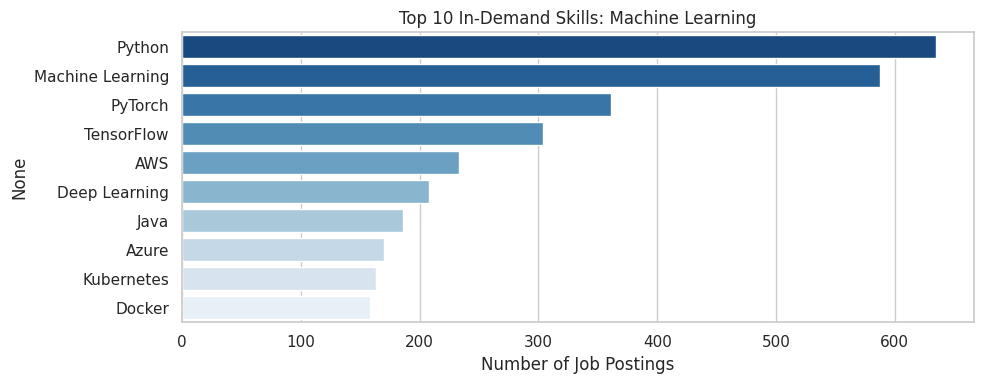

/tmp/ipykernel_12755/1894832339.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=skill_counts.values, y=skill_counts.index, palette='Blues_r')


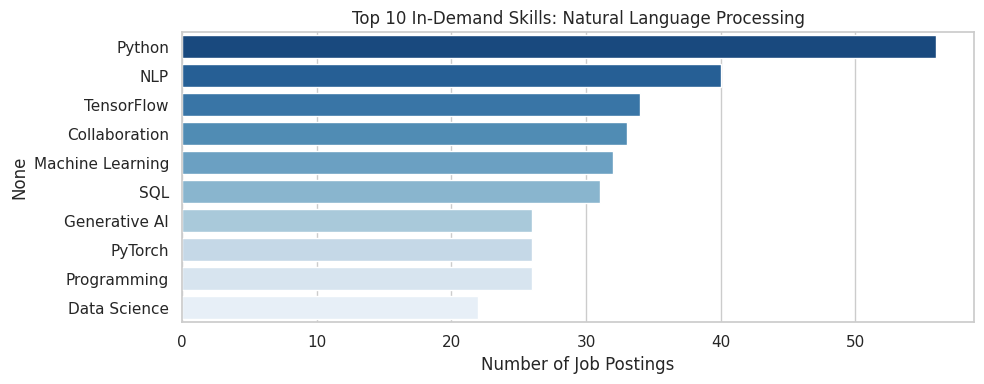

In [8]:
for domain in ['Machine Learning', 'Natural Language Processing']:
    domain_df = df_clean[df_clean['domain'] == domain]
    all_skills = []
    for skills_str in domain_df['job_skills']:
        skills = [s.strip() for s in str(skills_str).split(',') if s.strip()]
        all_skills.extend(skills)
        
    skill_counts = pd.Series(all_skills).value_counts().head(10)
    
    plt.figure(figsize=(10, 4))
    sns.barplot(x=skill_counts.values, y=skill_counts.index, palette='Blues_r')
    plt.title(f'Top 10 In-Demand Skills: {domain}')
    plt.xlabel('Number of Job Postings')
    plt.tight_layout()
    plt.show()

## Step 7: Sample Curriculum Alignment & Gap Analysis
Let's simulate how the system analyzes an academic course syllabus.

## Step 7: Comprehensive Curriculum Alignment & Gap Analysis
Let's analyze all university courses from courses.json and perform detailed gap analysis against industry skills.